# Практична робота 4. Дерево рішень і випадковий ліс

Варіант: bean 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay,
                             confusion_matrix)

VARIANT = 'bean'  
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)

df = pd.read_csv('drybean.csv')
target = 'Class'
features = [c for c in df.columns if c not in ('Class', 'split')]


train, val, test = (df[df['split'] == s] for s in ('train', 'val', 'test'))
X_tr, y_tr = train[features], train[target]
X_va, y_va = val[features], val[target]
X_te, y_te = test[features], test[target]

print('train: ', len(train))
print('validation:', len(val))
print('test: ', len(test))


train:  8164
validation: 2721
test:  2726


## Завдання 1. Знайомство з даними

Ознак: 16
 класів: 7
Ознаки: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


Class
DERMASON    2127
SIRA        1581
SEKER       1216
HOROZ       1156
CALI         978
BARBUNYA     793
BOMBAY       313
Name: count, dtype: int64
Найбільший клас / найменший = 6.80


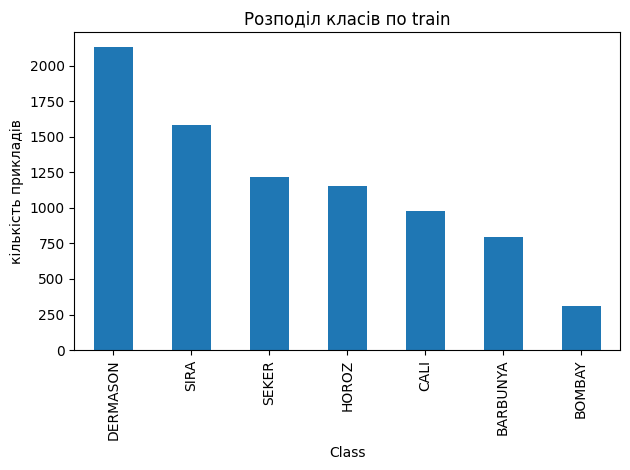

Лінива модель (DERMASON): accuracy на validation = 0.2606


In [5]:
print('Ознак:', len(features)) 
print(' класів:', df[target].nunique())
print('Ознаки:', features)


display(df[features + [target]].head())
display(df[features].describe().T)


counts = y_tr.value_counts()
print(counts)
print(f'Найбільший клас / найменший = {counts.max() / counts.min():.2f}')

counts.plot(kind='bar', title='Розподіл класів по train')
plt.ylabel('кількість прикладів')
plt.tight_layout()
plt.show()


majority = counts.idxmax()
lazy_pred = np.full(len(y_va), majority)
lazy_acc = accuracy_score(y_va, lazy_pred)
print(f'Лінива модель ({majority}): accuracy на validation = {lazy_acc:.4f}')


**Результат:**
- класів: 7
- ознак: 16
- Accuracy лінивої моделі на validation: 0.2606

## Завдання 2. Дерево рішень

Мета: навчити дерево глибини 3, побачити правила, які воно вивчило, і порахувати точність на train і validation. Порівняння цих двох точностей показує, чи не перенавчилася модель.


accuracy train:       0.7799
accuracy validation:  0.7725


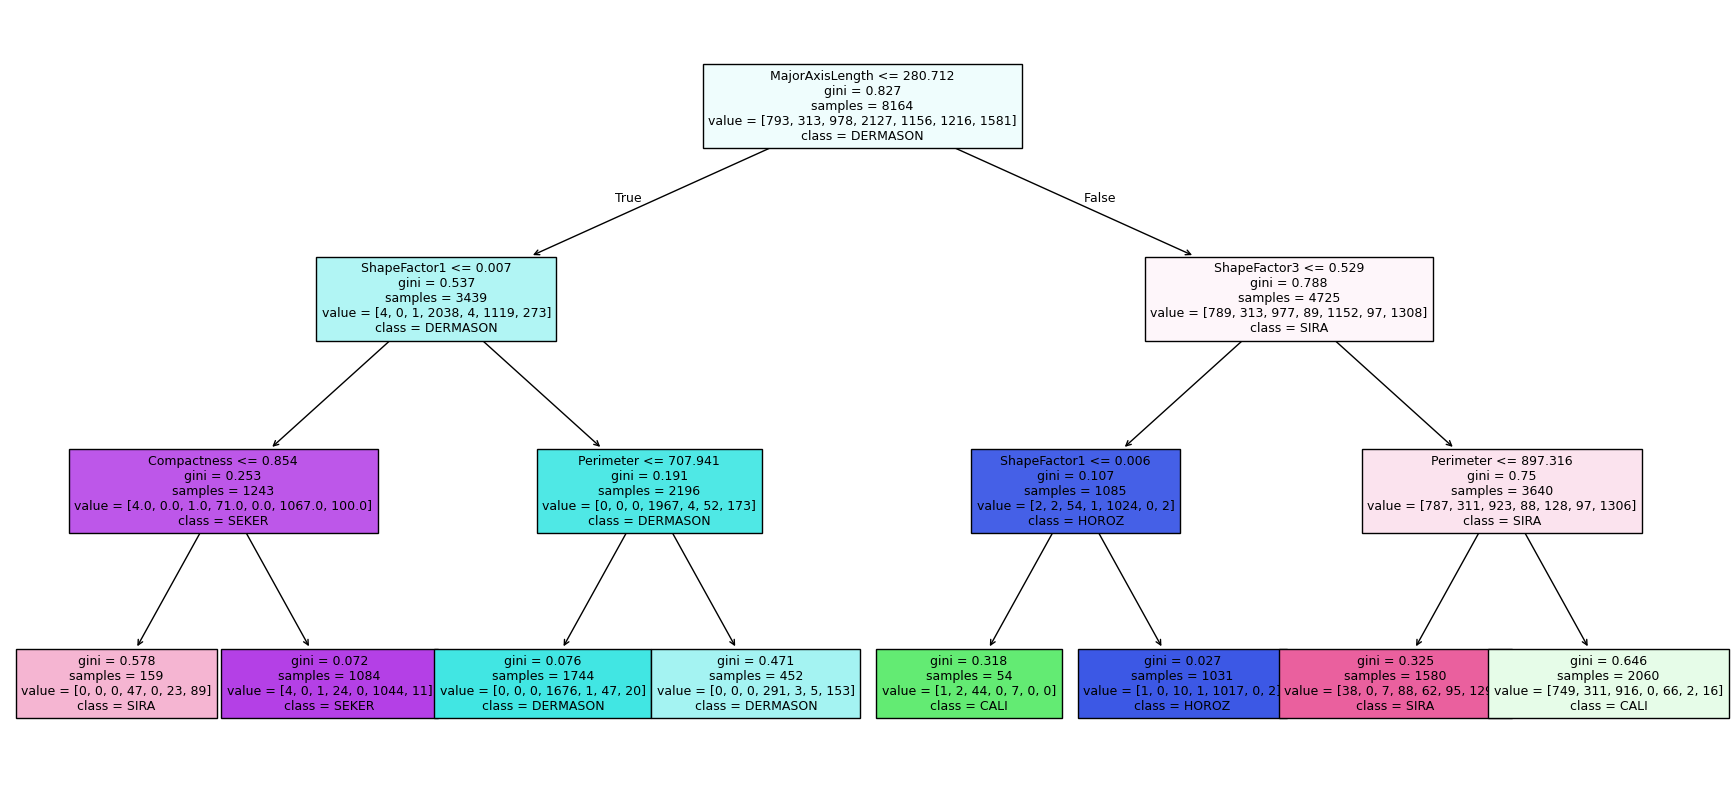

|--- MajorAxisLength <= 280.71
|   |--- ShapeFactor1 <= 0.01
|   |   |--- Compactness <= 0.85
|   |   |   |--- class: SIRA
|   |   |--- Compactness >  0.85
|   |   |   |--- class: SEKER
|   |--- ShapeFactor1 >  0.01
|   |   |--- Perimeter <= 707.94
|   |   |   |--- class: DERMASON
|   |   |--- Perimeter >  707.94
|   |   |   |--- class: DERMASON
|--- MajorAxisLength >  280.71
|   |--- ShapeFactor3 <= 0.53
|   |   |--- ShapeFactor1 <= 0.01
|   |   |   |--- class: CALI
|   |   |--- ShapeFactor1 >  0.01
|   |   |   |--- class: HOROZ
|   |--- ShapeFactor3 >  0.53
|   |   |--- Perimeter <= 897.32
|   |   |   |--- class: SIRA
|   |   |--- Perimeter >  897.32
|   |   |   |--- class: CALI

Перше питання: MajorAxisLength <= 280.712
якщо MajorAxisLength > 280.712 і ShapeFactor3 > 0.529 і Perimeter > 897.316, то клас CALI


In [6]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_tr, y_tr)

print('accuracy train:      ', round(accuracy_score(y_tr, tree.predict(X_tr)), 4))
print('accuracy validation: ', round(accuracy_score(y_va, tree.predict(X_va)), 4))

plt.figure(figsize=(22, 10))
plot_tree(tree, feature_names=features, class_names=list(tree.classes_), filled=True, fontsize=9)
plt.show()

print(export_text(tree, feature_names=features))


root_feature = features[tree.tree_.feature[0]]
print(f'Перше питання: {root_feature} <= {tree.tree_.threshold[0]:.3f}')


def leaf_rule(model, feature_names):
    t = model.tree_
    parent = {}
    for node in range(t.node_count):
        if t.children_left[node] != -1:
            parent[int(t.children_left[node])] = (node, '<=')
            parent[int(t.children_right[node])] = (node, '>')
    leaves = [i for i in range(t.node_count) if t.children_left[i] == -1]
    leaf = max(leaves, key=lambda i: t.n_node_samples[i])
    conditions, node = [], leaf
    while node in parent:
        p, op = parent[node]
        conditions.append(f'{feature_names[t.feature[p]]} {op} {t.threshold[p]:.3f}')
        node = p
    conditions.reverse()
    cls = model.classes_[np.argmax(t.value[leaf][0])]
    return 'якщо ' + ' і '.join(conditions) + f', то клас {cls}'


print(leaf_rule(tree, features))


Результат:
- Accuracy на train / validation: 0.7799 / 0.7725
- Правило словами (з виводу вище): якщо MajorAxisLength > 280.712 і ShapeFactor3 > 0.529 і Perimeter > 897.316, то клас CALI
- Перше питання дерева: MajorAxisLength


## Завдання 3. Випадковий ліс і порівняння

        accuracy  precision (macro)  recall (macro)
дерево    0.7725             0.5805          0.6407
ліс       0.9162             0.9291          0.9294


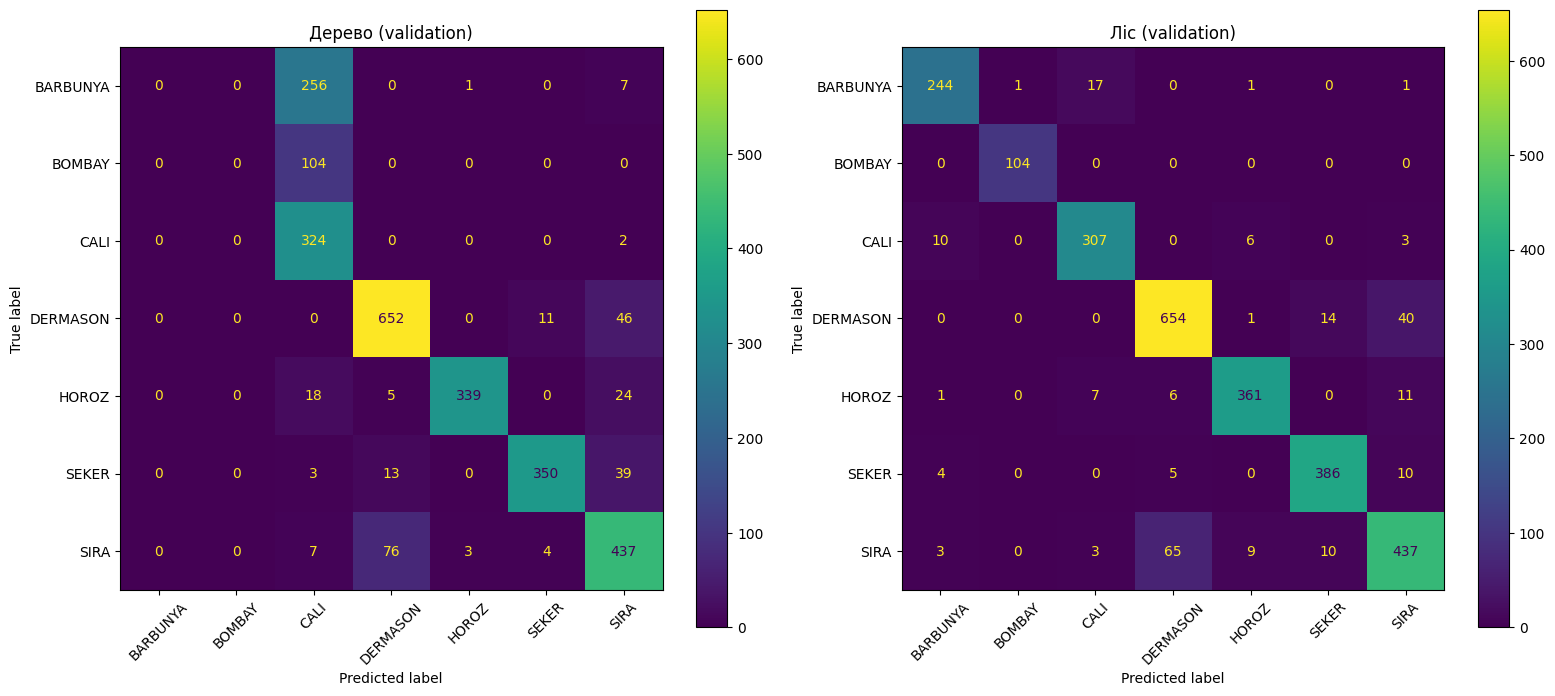

Найчастіше плутає: справжній SIRA -> прогноз DERMASON (65 разів)


In [13]:
forest = RandomForestClassifier(n_estimators=100, random_state=0)
forest.fit(X_tr, y_tr)


def scores(model, X, y):
    pred = model.predict(X)
    return {
        'accuracy': accuracy_score(y, pred),
        'precision (macro)': precision_score(y, pred, average='macro', zero_division=0),
        'recall (macro)': recall_score(y, pred, average='macro', zero_division=0),
    }


table = pd.DataFrame({'дерево': scores(tree, X_va, y_va),
                      'ліс': scores(forest, X_va, y_va)}).T
print(table.round(4))


fig, axes = plt.subplots(1, 2, figsize=(16, 7))
ConfusionMatrixDisplay.from_estimator(tree, X_va, y_va, ax=axes[0], xticks_rotation=45)
axes[0].set_title('Дерево (validation)')
ConfusionMatrixDisplay.from_estimator(forest, X_va, y_va, ax=axes[1], xticks_rotation=45)
axes[1].set_title('Ліс (validation)')
plt.tight_layout()
plt.show()


cls = forest.classes_
cm = confusion_matrix(y_va, forest.predict(X_va), labels=cls)
off = cm.copy()
np.fill_diagonal(off, 0)   # прибираємо правильні відповіді
i, j = np.unravel_index(off.argmax(), off.shape)
print(f'Найчастіше плутає: справжній {cls[i]} -> прогноз {cls[j]} ({off[i, j]} разів)')


**Результат:**
- Ліс краще за дерево на 0.1437.
- Найчастіше плутаються класи SIRA і DERMASON


## Завдання 4. Експеримент з параметрами

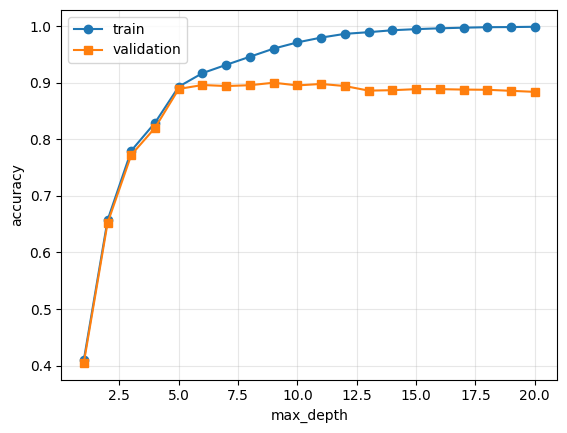

Найкраща глибина: 9, accuracy на validation = 0.9000367511944138


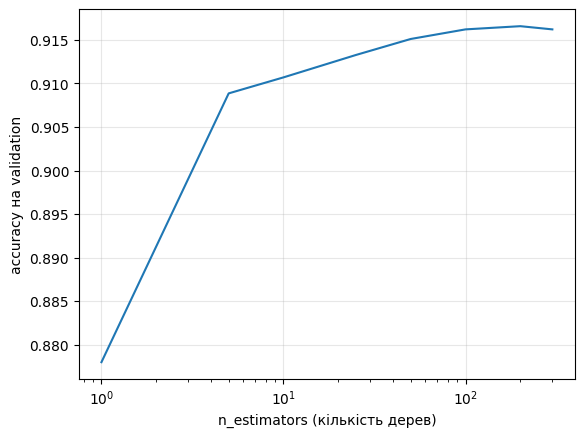

Найкраща кількість дерев: 200, accuracy на validation = 0.9166
Дерево на test: 0.8955
Ліс на test:    0.9189


In [15]:
depths = list(range(1, 21))
train_acc, val_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_tr, y_tr)
    train_acc.append(accuracy_score(y_tr, m.predict(X_tr)))
    val_acc.append(accuracy_score(y_va, m.predict(X_va)))

plt.plot(depths, train_acc, 'o-', label='train')
plt.plot(depths, val_acc, 's-', label='validation')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

best_i = int(np.argmax(val_acc))
best_depth = depths[best_i]
print(f'Найкраща глибина: {best_depth}, accuracy на validation = {val_acc[best_i]}')


n_trees = [1, 5, 10, 25, 50, 100, 200, 300]
forest_val_acc = []
for n in n_trees:
    f = RandomForestClassifier(n_estimators = n, random_state = 0, n_jobs = -1).fit(X_tr, y_tr)
    forest_val_acc.append(accuracy_score(y_va, f.predict(X_va)))

plt.plot(n_trees, forest_val_acc)
plt.xscale('log')
plt.xlabel('n_estimators (кількість дерев)')
plt.ylabel('accuracy на validation')
plt.grid(alpha=0.3)
plt.show()

best_n = n_trees[int(np.argmax(forest_val_acc))]
print(f'Найкраща кількість дерев: {best_n}, accuracy на validation = {max(forest_val_acc):.4f}')


best_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=0).fit(X_tr, y_tr)
best_forest = RandomForestClassifier(n_estimators=best_n, random_state=0, n_jobs=-1).fit(X_tr, y_tr)
print('Дерево на test:', round(accuracy_score(y_te, best_tree.predict(X_te)), 4))
print('Ліс на test:   ', round(accuracy_score(y_te, best_forest.predict(X_te)), 4))


**Результат:**
- Перенавчання починається з глибини: 10
- Достатньо дерев: 9

## Завдання 5. Важливість ознак

Мета: з'ясувати, які ознаки найважливіші для лісу, і перевірити, чи стане гірше, якщо залишити лише їх. Якщо точність майже не падає, модель тримається на цих ознаках.


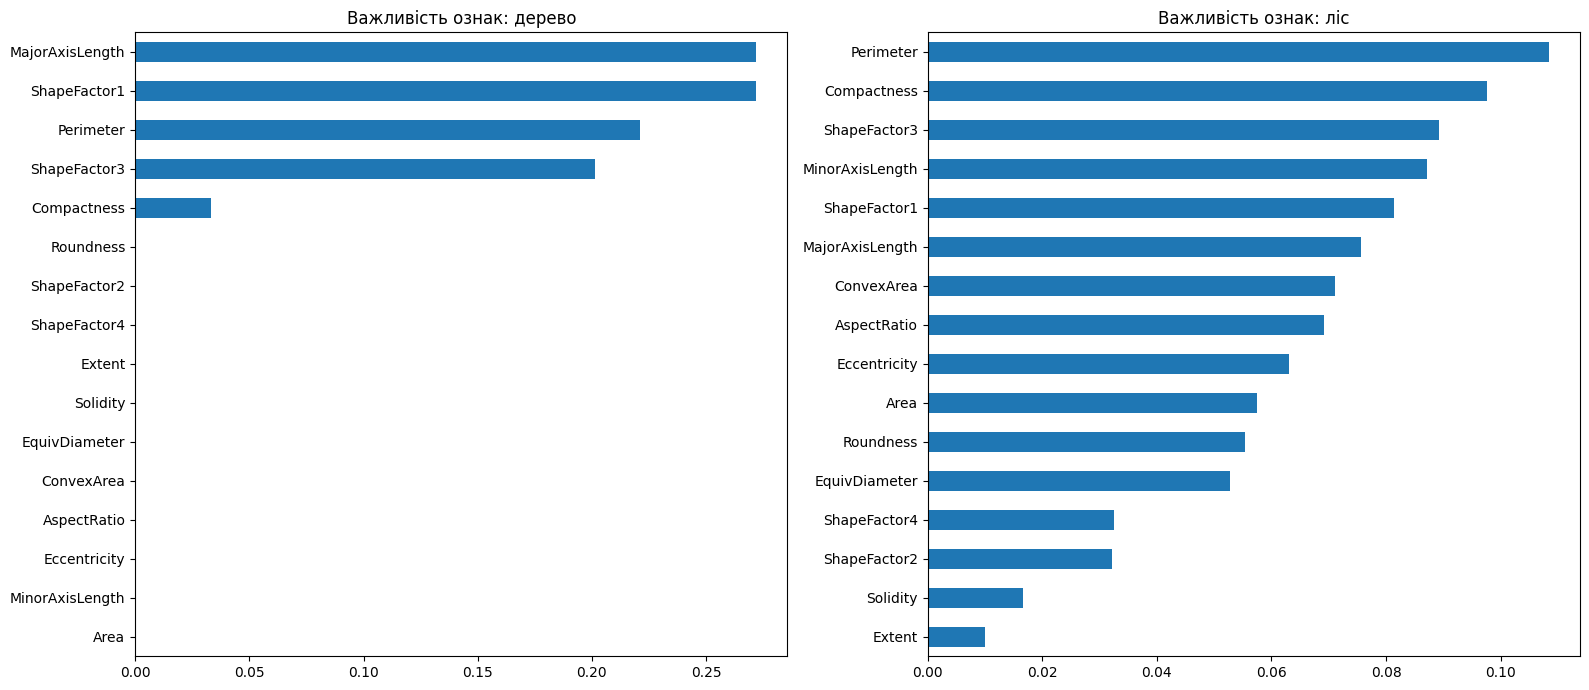

Три найважливіші ознаки лісу:
Perimeter       0.1084
Compactness     0.0976
ShapeFactor3    0.0893
dtype: float64
            повний ліс  змінений ліс
validation      0.9162        0.8736
test            0.9153        0.8687


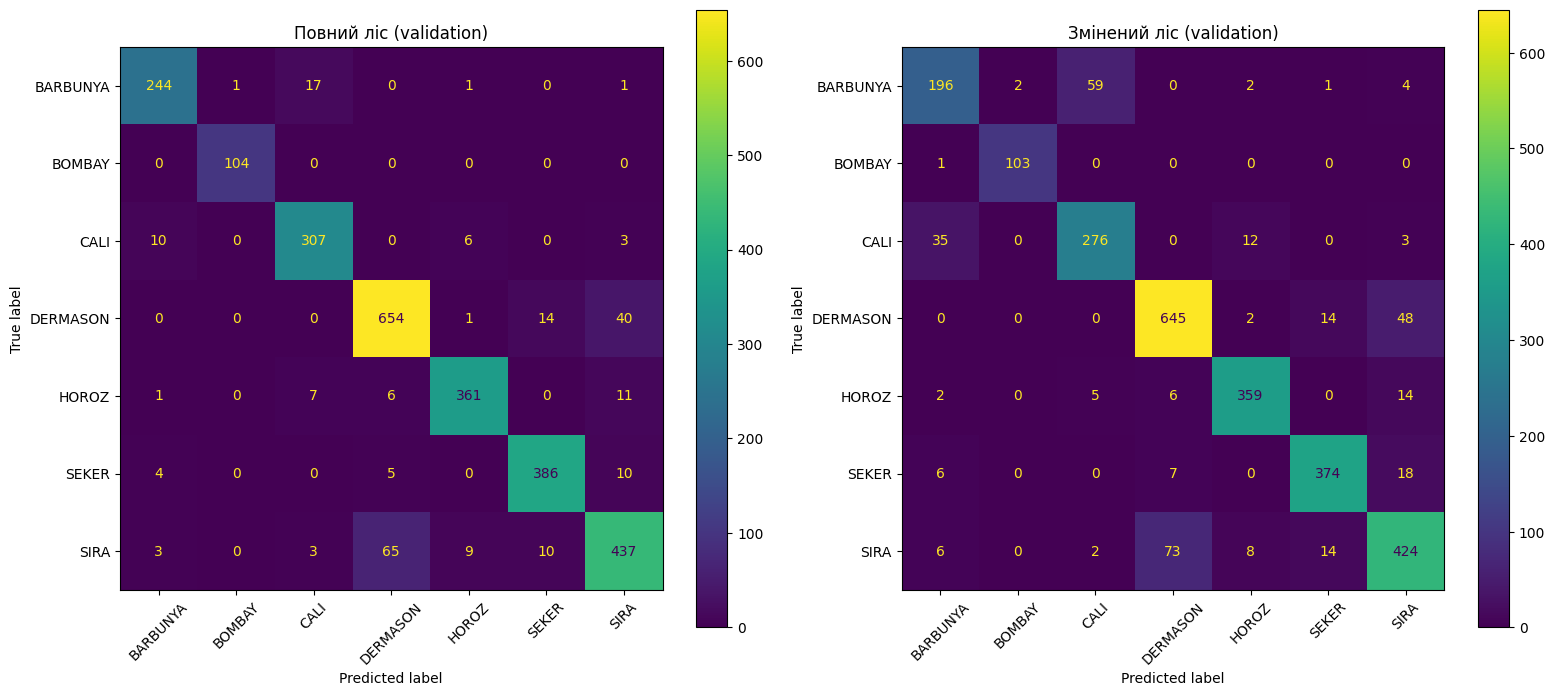

In [16]:
imp_tree = pd.Series(tree.feature_importances_, index=features)
imp_forest = pd.Series(forest.feature_importances_, index=features)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
imp_tree.sort_values().plot(kind='barh', ax=axes[0], title='Важливість ознак: дерево')
imp_forest.sort_values().plot(kind='barh', ax=axes[1], title='Важливість ознак: ліс')
plt.tight_layout()
plt.show()

top3 = imp_forest.sort_values(ascending=False).head(3)
print('Три найважливіші ознаки лісу:')
print(top3.round(4))

reduced = list(top3.index)


forest_red = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
forest_red.fit(X_tr[reduced], y_tr)

compare = pd.DataFrame({
    'повний ліс': [accuracy_score(y_va, forest.predict(X_va)),
                   accuracy_score(y_te, forest.predict(X_te))],
    'змінений ліс': [accuracy_score(y_va, forest_red.predict(X_va[reduced])),
                     accuracy_score(y_te, forest_red.predict(X_te[reduced]))],
}, index=['validation', 'test'])
print(compare.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
ConfusionMatrixDisplay.from_estimator(forest, X_va, y_va, ax=axes[0], xticks_rotation=45)
axes[0].set_title('Повний ліс (validation)')
ConfusionMatrixDisplay.from_estimator(forest_red, X_va[reduced], y_va, ax=axes[1], xticks_rotation=45)
axes[1].set_title('Змінений ліс (validation)')
plt.tight_layout()
plt.show()


**Результат:**
- Три найважливіші ознаки і що вони означають: Perimeter - периметр, Compactness - наскільки форма подібна до сфери, ShapeFactor3 - наскільки форма подібна до еліпса
- Що змінилося після зміни набору ознак і чому: змінилася точність моделі (зменшилась) оскільки модель перестала враховувати всі параметри


## Завдання 6. Нові випадки

In [18]:

med_sira = X_tr[y_tr == 'SIRA'].median()
med_seker = X_tr[y_tr == 'CALI'].median()
examples = pd.DataFrame([med_sira, (med_sira + med_seker) / 2, med_seker]).reset_index(drop=True)
examples.index = ['медіана SIRA', 'між SIRA і CALI', 'медіана CALI']


examples = examples[features]

result = pd.DataFrame({'дерево': best_tree.predict(examples),
                       'ліс': best_forest.predict(examples)}, index=examples.index)
proba = pd.DataFrame(best_forest.predict_proba(examples), index=examples.index,
                     columns=best_forest.classes_).round(3)
display(pd.concat([result, proba], axis=1))

print('Приклади, де дерево і ліс відповіли по-різному:')
print(result[result['дерево'] != result['ліс']])


,дерево,ліс,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
медіана SIRA,SIRA,SIRA,0.000,0.0,0.000,0.0,0.000,0.0,1.00
між SIRA і CALI,BARBUNYA,CALI,0.275,0.0,0.590,0.0,0.045,0.0,0.09
медіана CALI,CALI,CALI,0.005,0.0,0.995,0.0,0.000,0.0,0.00


Приклади, де дерево і ліс відповіли по-різному:
                   дерево   ліс
між SIRA і CALI  BARBUNYA  CALI


**Результат:**
- Пояснення, чому моделі відповіли по-різному (або однаково): моделі відповіли однаково, бо всі приклади лежать в зонах, які добре розділяються обома моделями (у випадку порівняння SIRA i SEEKER), при порівнянні SIRA і CALI моделі дають різні прогнози


## Завдання 7. Порахувати руками

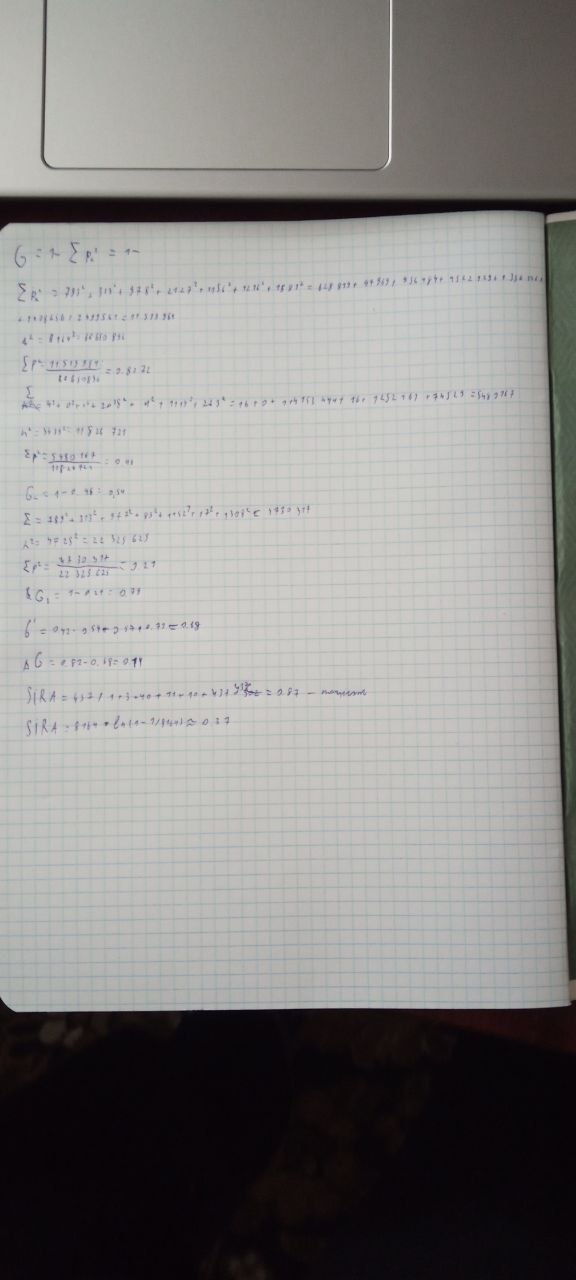